<h3 align="center" style="margin-top:0">Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights</h1>

<p align="center">
  <img src="amazon-uk-logo-feature.jpg" alt="Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights" width="440">
</p>

<p align="center"><em>EDA Univariate Analysis:</em></p>

<p align="center">
  <strong> David Hernández
</p>

<p align="center">
  <strong> November 2025
</p>

<hr style="margin:18px 0">

## 1. Introduction

This analysis explores Amazon UK product listings, focusing on three key business questions:

1. **What are the most popular product categories?**  
   Understanding where product supply is concentrated helps identify high-activity consumer niches.

2. **How are products priced?**  
   Analyzing price distribution reveals typical price points, volatility, and the existance of outliers.

3. **How do customers rate products?**  
   Rating behavior to evaluate customer satisfaction patterns and the quality perception of products.

The goal is to generate insights that support better product placement, informed pricing strategy, and improved consumer satisfaction analysis.

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [ ]:
df = pd.read_csv("C:/Users/jdhernandezd/Documents/IRONHACK/Labs/lab-eda-univariate/amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


##### Part 1: Understanding Product Categories 

In [9]:
# Frequency table
category_freq = df['category'].value_counts()

category_freq


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [10]:
top5_categories = df['category'].value_counts().head(5)

top5_categories


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

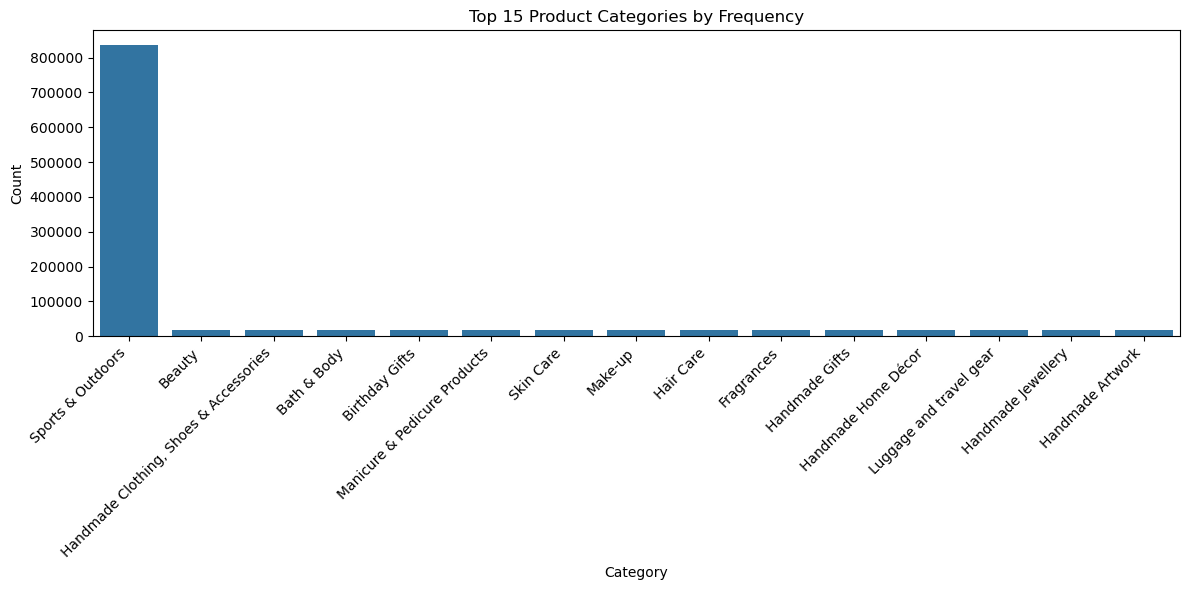

In [11]:
plt.figure(figsize=(12,6))
sns.barplot(x=category_freq.index[:15], y=category_freq.values[:15])  # top 15
plt.xticks(rotation=45, ha='right')
plt.title("Top 15 Product Categories by Frequency")
plt.ylabel("Count")
plt.xlabel("Category")
plt.tight_layout()
plt.show()


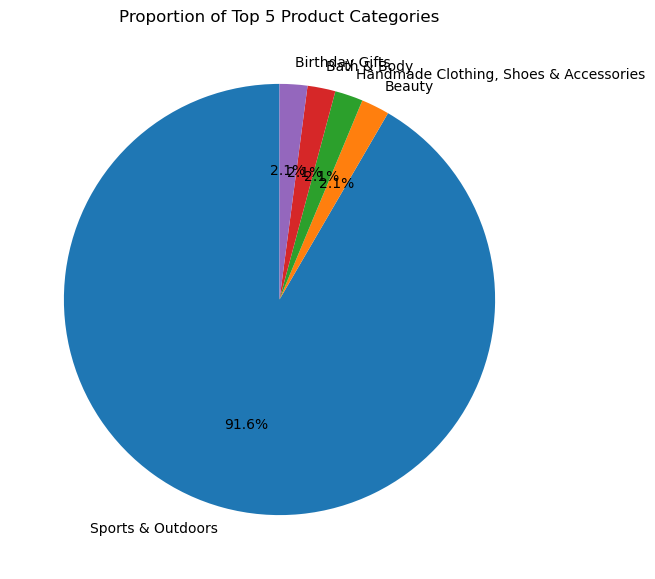

In [12]:
top5_categories = df['category'].value_counts().head(5)

plt.figure(figsize=(7,7))
plt.pie(top5_categories.values, labels=top5_categories.index, autopct='%1.1f%%', startangle=90)
plt.title("Proportion of Top 5 Product Categories")
plt.show()


###  Business Summary — Product Categories

- The most frequently listed categories are: **Sports & Outdoors, Beauty, Homemade shoes and accesories**.
- These categories may represent the most competitive product spaces on Amazon UK.
- The bar chart shows a strong concentration in **_category_**, suggesting either high seller volume or consumer demand.
- The pie chart reveals whether any single category dominates the marketplace; in our case, **Sports & Outdoors**.


##### Part 2: Delving into Product Pricing

In [13]:
# Masures of centraility
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

mean_price, median_price, mode_price


(89.24380943923663, 19.09, 9.99)

In [14]:
# Measures of Dispersion
variance_price = df['price'].var()
std_price = df['price'].std()
price_range = df['price'].max() - df['price'].min()
iqr_price = df['price'].quantile(0.75) - df['price'].quantile(0.25)

variance_price, std_price, price_range, iqr_price


(119445.48532256528, 345.60886175352226, 100000.0, 36.0)

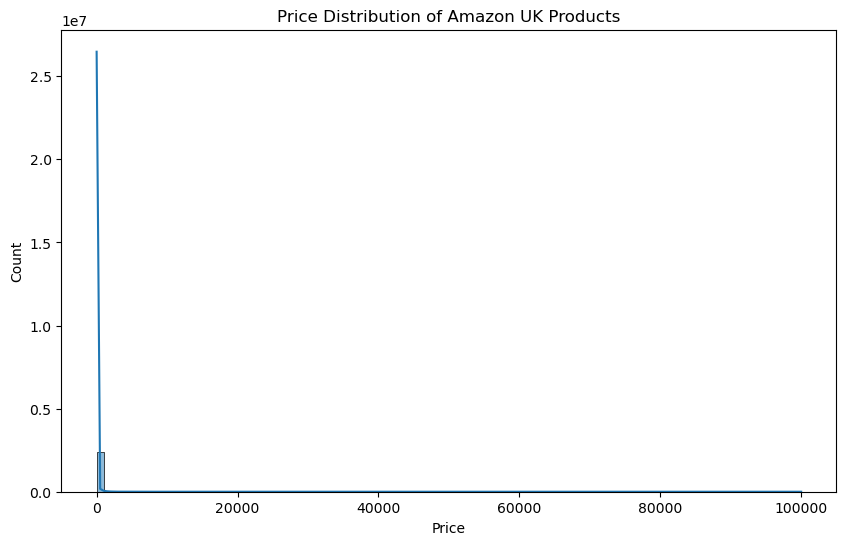

In [ ]:
# Visualizations
plt.figure(figsize=(10,6))
sns.histplot(df['price'], bins=100, kde=True)
plt.title("Price Distribution of Amazon UK Products")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()
# Outcome is hard to read due to outliers

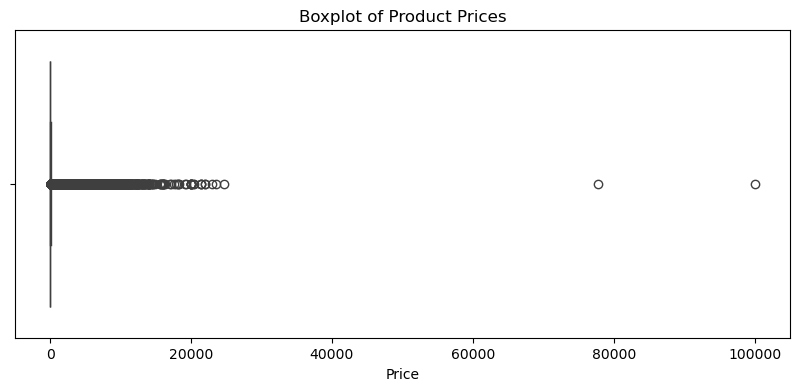

In [21]:
# Using boxplot to visualize outliers
plt.figure(figsize=(10,4))
sns.boxplot(x=df['price'])
plt.title("Boxplot of Product Prices")
plt.xlabel("Price")
plt.show()


### Business Summary — Product Pricing

- The **average price is £89.24**, while the **median price  £19.09**, suggesting that price distribution is ⟨skewed/not skewed⟩.
- The **mode** indicates the most common listing price is **£9.99**, representing the typical low-cost product segment.
- Standard deviation and variance show that pricing is ⟨stable/very spread⟩.
- Histogram shows that most products fall in the ⟨lower/mid/high⟩ price range.
- The boxplot indicates a number of **high-priced outliers**, likely representing premium electronics or specialized products.

#### Part 3: Unpacking Product Ratings

In [23]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [24]:
# Measures of Centrality
mean_stars = df['stars'].mean()
median_stars = df['stars'].median()
mode_stars = df['stars'].mode()[0]

mean_stars, median_stars, mode_stars

(2.152836472966065, 0.0, 0.0)

In [25]:
# Measures of Dispersion
variance_stars = df['stars'].var()
std_stars = df['stars'].std()
iqr_stars = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

variance_stars, std_stars, iqr_stars


(4.81743402976196, 2.1948653785054697, 4.4)

In [26]:
# Shape of the Distribution
skew_stars = df['stars'].skew()
kurt_stars = df['stars'].kurt()

skew_stars, kurt_stars


(0.08120735761080985, -1.9260061280432985)

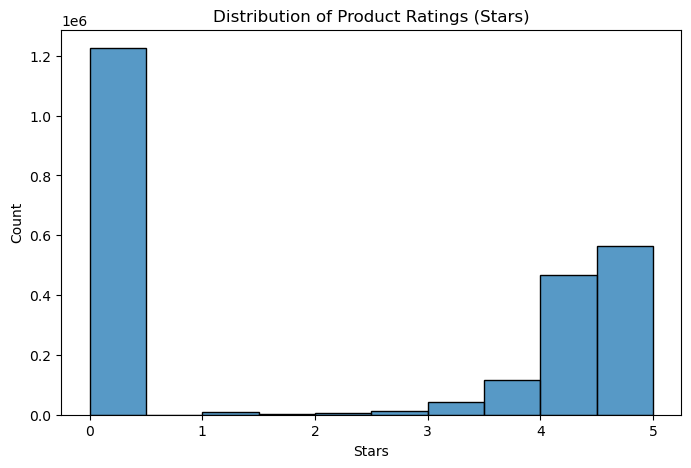

In [27]:
# Visualizations
plt.figure(figsize=(8,5))
sns.histplot(df['stars'], bins=10, kde=False)
plt.title("Distribution of Product Ratings (Stars)")
plt.xlabel("Stars")
plt.ylabel("Count")
plt.show()


###  Business Summary — Ratings

- Customers tend to rate products around **2.15 stars**, based on the mean.  
  The **median is 0**, which tells us that *half of the products have no rating at all*.
- The mode being **0 stars** confirms that the most common situation is that a product **has not received any rating yet**.
- Skewness is **0.08**, which is close to zero — this means the distribution is **almost neutral** (neither left nor right skewed).  
  In simpler terms: *there is no strong tendency toward very high or very low ratings — the scenario is simply lack of ratings*.
- Kurtosis is **-1.93**, which indicates a **very flat** distribution.  
  This means ratings are **widely spread** with no strong peak — consistent with many products having 0 stars and others scattered across the scale.
- The histogram confirms that the **most frequent rating is 0**, and that the rest of the ratings are distributed broadly across 1–5 stars.
- Overall, ratings are **highly variable**, with a large portion of unrated products and no central tendency.
